# Trabalho Final — Visão Computacional e Percepção
## Notebook 2 — Validação híbrida AR + MG

**Pergunta:** ao treinar com amostras das duas doenças e testar em amostras retidas das duas, o desempenho muda em relação ao Zero-Shot do notebook 1? Se mudar, o ganho vem do maior volume de treino, do fato de testarmos MG contra MG, ou de outro fator?

| Papel | Dataset | Doença | Amostras | Rótulo | Plataforma |
|---|---|---|---:|---|---|
| Treino | GSE106894 | Artrite reumatoide | 8 (4 R / 4 NR) | R/NR explícito | Affymetrix miRNA 4.0 |
| Treino | GSE131703 | Miastenia Gravis | 24 (12 R / 12 NR) | R/NR explícito | miRNA-seq |
| Teste | GSE106894 | Artrite reumatoide | 4 (2 R / 2 NR) | R/NR explícito | Affymetrix miRNA 4.0 |
| Teste | GSE131703 | Miastenia Gravis | 6 (3 R / 3 NR) | R/NR explícito | miRNA-seq |

**Desenho:** holdout estratificado por doença e por desfecho, com semente fixa. O notebook 1 (Zero-Shot) é a linha de base; aqui o teste **não é** Zero-Shot, pois contém amostras das mesmas duas coortes usadas no treino.

> **Premissa de nomenclatura:** o enunciado cita "GSE3703" no teste. Como não existe essa base no projeto e o GSE131703 tem 30 amostras, interpretamos "GSE3703" como **GSE131703**. Assim, 30 − 24 = **6 amostras de GSE131703** vão para o teste.

## Raciocínio experimental

O notebook 1 treinou apenas em AR e testou apenas em MG. O resultado foi negativo (AUC 0,436). Duas explicações concorrentes continuam abertas:

1. o sinal é específico de cada doença e não transfere entre AR e MG;
2. o pipeline linear com n = 12 no treino é incapaz de capturar a relação, que pode ser não linear.

Neste notebook, o treino passa a conter as duas doenças e o teste também. Isso permite separar três efeitos:

- **volume de dados:** 32 amostras de treino em vez de 12;
- **compatibilidade de domínio:** 6 das 10 amostras de teste são MG, então parte do teste é "MG contra MG";
- **fator externo:** qualquer ganho que não seja explicado por volume nem por domínio.

**Hipótese avançada:** se o desempenho permanecer na mesma faixa do notebook 1, há indício de que a relação entre expressão de miRNA e resposta não é capturável por este modelo linear, e não apenas de que a transferência entre doenças falha. Se houver melhora, é preciso decompor o ganho antes de atribuí-lo ao modelo.

**Cuidado central:** este teste não é Zero-Shot. As amostras de teste vêm das mesmas coortes do treino, então o número deve ser lido como desempenho em holdout híbrido, não como generalização para uma doença nova.

### Dependências

```bash
pip install pandas numpy scikit-learn matplotlib seaborn GEOparse openpyxl
```

In [1]:
# Bibliotecas padrão: logging, avisos, contagem e manipulação de caminhos.
import logging
import warnings
from collections import Counter
from pathlib import Path

# Bibliotecas de dados, gráficos e acesso aos datasets do GEO.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import GEOparse
from IPython.display import display

# Componentes de modelagem, validação, métricas e seleção de features.
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    LeaveOneOut,
    RepeatedStratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Configuração global: silencia avisos, define estilo dos gráficos e caminhos.
warnings.filterwarnings("ignore")
logging.getLogger("GEOparse").setLevel(logging.WARNING)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42
N_TEST_AR = 4
N_TEST_MG = 6
N_REPEATS = 50
RESULT_PREFIX = "vcp2"

DATA_DIR = Path("datasets")
RESULTS_DIR = Path("resultados")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print("Configuração concluída.")

Configuração concluída.


## Etapa 1 — Carregamento e anotação

As funções de carregamento são as mesmas do notebook 1: sondas Affymetrix são convertidas em nomes de miRNA, sondas duplicadas são agregadas pela média e as contagens do GSE131703 são normalizadas por log-CPM. O alinhamento entre as bases usa apenas a interseção dos nomes de miRNA, sem rótulos.

In [2]:
def _download(url: str, path: Path) -> Path:
    '''Baixa um arquivo apenas se ele ainda não existir localmente.'''
    if not path.exists():
        import urllib.request
        urllib.request.urlretrieve(url, path)
    return path


def _parse_response(value) -> float:
    '''Converte o rótulo textual do GSE106894 para 1 (R) / 0 (NR).'''
    text = str(value).strip().lower()
    if text in {"responder", "r", "1"}:
        return 1.0
    if text in {"non-responder", "non responder", "nr", "0"}:
        return 0.0
    return np.nan


def _parse_mg_label(sample: str) -> float:
    '''Extrai o rótulo do GSE131703 a partir do nome da amostra.'''
    if "_NR" in sample:
        return 0.0
    if "_R" in sample:
        return 1.0
    return np.nan


def _log_cpm(counts: pd.DataFrame) -> pd.DataFrame:
    '''Normaliza contagens por log-CPM, adequado para dados de RNA-seq.'''
    library = counts.sum(axis=1).replace(0, np.nan)
    return np.log1p(counts.div(library, axis=0) * 1e6).fillna(0.0)


def load_gse106894(data_dir: Path = DATA_DIR) -> dict:
    '''Carrega o GSE106894 e anota sondas Affymetrix como miRNAs.'''
    # Abre o dataset já baixado (ou baixa, se ainda não existir).
    gse = GEOparse.get_GEO(geo="GSE106894", destdir=str(data_dir), silent=True)

    # Matriz de expressão: linhas = amostras, colunas = sondas.
    expression = gse.pivot_samples("VALUE").T

    # Anotação da plataforma Affymetrix: ID da sonda -> nome do miRNA.
    platform = gse.gpls[next(iter(gse.gpls))]
    annotation = platform.table[["ID", "miRNA_ID"]].copy()
    annotation["ID"] = annotation["ID"].astype(str)
    annotation["miRNA_ID"] = (
        annotation["miRNA_ID"].fillna("").astype(str).str.strip()
    )
    annotation = annotation[annotation["miRNA_ID"] != ""].drop_duplicates("ID")
    probe_to_mirna = dict(zip(annotation["ID"], annotation["miRNA_ID"]))

    # Troca os IDs de sonda pelos nomes de miRNA.
    expression.columns = [
        probe_to_mirna.get(str(column), "") for column in expression.columns
    ]
    # Descarta sondas que não têm anotação de miRNA.
    expression = expression.loc[:, expression.columns != ""]
    # Várias sondas podem apontar para o mesmo miRNA; agrega pela média.
    expression = expression.T.groupby(level=0).mean().T
    expression = expression.apply(pd.to_numeric, errors="coerce").fillna(0.0)

    # Lê o rótulo clínico de resposta ao tratamento (R/NR).
    metadata = gse.phenotype_data
    response_column = next(
        column for column in metadata.columns if "response" in column.lower()
    )
    labels = (
        metadata[response_column]
        .map(_parse_response)
        .reindex(expression.index)
    )
    keep = labels.notna()

    expression = expression.loc[keep]
    labels = labels.loc[keep].astype(int)
    expression.index.name = "sample"
    labels.name = "response"

    # Devolve a matriz de expressão e o vetor de rótulos alinhados.
    return {
        "name": "GSE106894",
        "X": expression,
        "y": labels,
        "platform": "GPL21572",
    }

In [3]:
GSE131703_URL = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE131nnn/GSE131703/suppl/"
    "GSE131703_Rawcounts_MiRNA_MG_R_NR.xlsx"
)


def load_gse131703(data_dir: Path = DATA_DIR) -> dict:
    '''Carrega o GSE131703 (miRNA-seq) e normaliza as contagens por log-CPM.'''
    # Garante que o arquivo XLSX de contagens esteja disponível localmente.
    path = _download(
        GSE131703_URL, data_dir / "GSE131703_Rawcounts_MiRNA_MG_R_NR.xlsx"
    )
    # Lê a aba com as contagens brutas por miRNA.
    raw = pd.read_excel(path, sheet_name="mirna_rawcounts")

    # As colunas de amostra do arquivo começam com "MG_".
    sample_columns = [
        column for column in raw.columns if str(column).startswith("MG_")
    ]
    # Agrupa as contagens pelo nome do miRNA (pode haver mais de uma linha).
    counts = raw.groupby("Name")[sample_columns].sum()

    # Transpõe para o formato amostras x miRNAs e normaliza por log-CPM.
    expression = _log_cpm(counts.T.astype(float))
    expression.index = [str(sample) for sample in expression.index]

    # O rótulo está no nome da amostra: MG_R* = respondedor; MG_NR* = não-respondedor.
    labels = pd.Series(
        [_parse_mg_label(sample) for sample in expression.index],
        index=expression.index,
        name="response",
    )
    keep = labels.notna()

    expression = expression.loc[keep]
    labels = labels.loc[keep].astype(int)
    expression.index.name = "sample"

    return {
        "name": "GSE131703",
        "X": expression,
        "y": labels,
        "platform": "miRNA-seq",
    }


def align_domains(source: dict, target: dict) -> tuple[dict, dict, list[str]]:
    '''Alinha treino e teste pela interseção de miRNAs, sem usar rótulos.'''
    # Interseção calculada apenas com nomes de miRNAs; não usa rótulos.
    common = sorted(set(source["X"].columns) & set(target["X"].columns))
    if not common:
        raise ValueError("Nenhum miRNA em comum entre treino e teste.")

    source_aligned = {**source, "X": source["X"].loc[:, common].copy()}
    target_aligned = {**target, "X": target["X"].loc[:, common].copy()}
    return source_aligned, target_aligned, common

## Etapa 2 — Divisão híbrida e estratificada

A divisão é feita **separadamente em cada coorte** e depois empilhada. A estratificação garante:

- GSE106894: 4 R + 4 NR no treino e 2 R + 2 NR no teste;
- GSE131703: 12 R + 12 NR no treino e 3 R + 3 NR no teste.

A semente é fixa para que o notebook seja reprodutível. Nenhum rótulo do teste participa do ajuste de scaler, LASSO ou SVM.

In [4]:
# Carrega as duas bases e mantém apenas os miRNAs presentes em ambas.
source = load_gse106894()
target = load_gse131703()
source, target, common_features = align_domains(source, target)

# Empilha as duas coortes já alinhadas no mesmo espaço de features.
X_all = pd.concat([source["X"], target["X"]], axis=0)
y_all = pd.concat([source["y"], target["y"]], axis=0)
meta_all = pd.DataFrame(
    {
        "dataset": ["GSE106894"] * len(source["X"])
        + ["GSE131703"] * len(target["X"]),
        "response": np.concatenate(
            [source["y"].to_numpy(), target["y"].to_numpy()]
        ),
    },
    index=X_all.index,
)

# Quantidade de amostras na coorte de artrite reumatoide (AR).
N_AR = len(source["X"])


def split_stratified_positions(
    y: pd.Series,
    n_ar: int,
    n_test_ar: int = N_TEST_AR,
    n_test_mg: int = N_TEST_MG,
    seed: int = RANDOM_STATE,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    '''Sorteia treino/teste dentro de AR e MG, estratificando pelo desfecho.'''
    y_array = np.asarray(y)
    ar_positions = np.arange(n_ar)
    mg_positions = np.arange(n_ar, len(y_array))

    ar_train, ar_test = train_test_split(
        ar_positions,
        test_size=n_test_ar,
        stratify=y_array[ar_positions],
        random_state=seed,
    )
    mg_train, mg_test = train_test_split(
        mg_positions,
        test_size=n_test_mg,
        stratify=y_array[mg_positions],
        random_state=seed,
    )
    return tuple(
        np.sort(part)
        for part in (ar_train, ar_test, mg_train, mg_test)
    )


# Divisão principal do notebook: semente fixa.
ar_train, ar_test, mg_train, mg_test = split_stratified_positions(
    y_all, N_AR, N_TEST_AR, N_TEST_MG, RANDOM_STATE
)
train_idx = np.concatenate([ar_train, mg_train])
test_idx = np.concatenate([ar_test, mg_test])

# Matrizes e metadados das partições.
X_train = X_all.iloc[train_idx]
y_train = y_all.iloc[train_idx]
meta_train = meta_all.iloc[train_idx]

X_test = X_all.iloc[test_idx]
y_test = y_all.iloc[test_idx]
meta_test = meta_all.iloc[test_idx]


def resumo_particao(meta: pd.DataFrame, nome: str) -> None:
    '''Imprime a composição de uma partição por coorte e desfecho.'''
    table = (
        pd.crosstab(meta["dataset"], meta["response"])
        .rename(columns={0: "NR", 1: "R"})
    )
    table["total"] = table.sum(axis=1)
    print(f"\n{nome} ({len(meta)} amostras)")
    print(table)


print(f"miRNAs em comum entre AR e MG: {len(common_features)}")
resumo_particao(meta_train, "Treino")
resumo_particao(meta_test, "Teste")

# Auditoria da divisão: permite reconstruir exatamente quem ficou onde.
particao = pd.Series(index=X_all.index, dtype=object)
particao.iloc[train_idx] = "treino"
particao.iloc[test_idx] = "teste"
split_audit = (
    meta_all.assign(particao=particao)
    .rename_axis("amostra")
    .reset_index()
)
split_audit.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_split_hibrido.csv", index=False
)

display(split_audit.head(10))

miRNAs em comum entre AR e MG: 2578

Treino (32 amostras)
response   NR   R  total
dataset                 
GSE106894   4   4      8
GSE131703  12  12     24

Teste (10 amostras)
response   NR  R  total
dataset                
GSE106894   2  2      4
GSE131703   3  3      6


,amostra,dataset,response,particao
0,GSM2857226,GSE106894,0,treino
1,GSM2857227,GSE106894,0,treino
2,GSM2857228,GSE106894,0,treino
3,GSM2857229,GSE106894,0,teste
4,GSM2857230,GSE106894,0,teste
5,GSM2857231,GSE106894,0,treino
6,GSM2857232,GSE106894,1,treino
7,GSM2857233,GSE106894,1,treino
8,GSM2857234,GSE106894,1,treino
9,GSM2857235,GSE106894,1,treino


## Etapa 3 — Análise exploratória

A EDA é descritiva. O objetivo é verificar o balanceamento das partições e se as duas coortes ocupam regiões diferentes no espaço de miRNAs. Uma separação forte por coorte na PCA indica efeito de plataforma/tecido, que pode dominar a classificação.

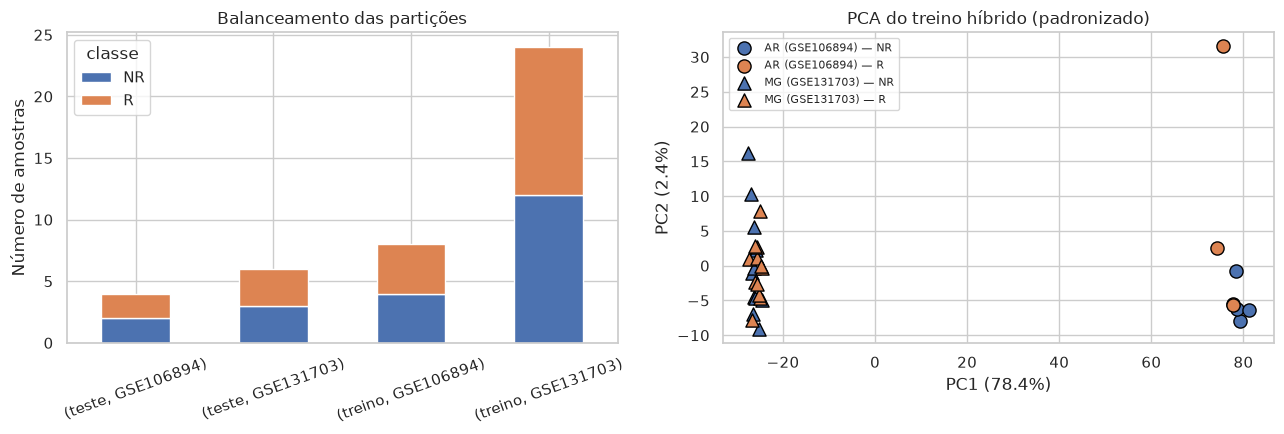

Variância explicada pelas duas primeiras PCs: 80.8%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Balanceamento por partição, coorte e classe.
balance = (
    split_audit.assign(classe=split_audit["response"].map({0: "NR", 1: "R"}))
    .groupby(["particao", "dataset", "classe"])
    .size()
    .unstack(fill_value=0)
)
balance.plot(
    kind="bar", stacked=True, ax=axes[0], color=["#4c72b0", "#dd8452"]
)
axes[0].set_title("Balanceamento das partições")
axes[0].set_ylabel("Número de amostras")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

# PCA do treino: cor = desfecho; marcador = coorte.
scaler_eda = StandardScaler().fit(X_train)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_coords = pca.fit_transform(scaler_eda.transform(X_train))

for domain, marker, domain_label in [
    ("GSE106894", "o", "AR (GSE106894)"),
    ("GSE131703", "^", "MG (GSE131703)"),
]:
    for response, color in [(0, "#4c72b0"), (1, "#dd8452")]:
        mask = (
            (meta_train["dataset"] == domain)
            & (meta_train["response"] == response)
        ).to_numpy()
        axes[1].scatter(
            pca_coords[mask, 0],
            pca_coords[mask, 1],
            marker=marker,
            color=color,
            s=90,
            edgecolor="black",
            label=f"{domain_label} — {'R' if response else 'NR'}",
        )
axes[1].set_title("PCA do treino híbrido (padronizado)")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[1].legend(fontsize=8, frameon=True)
plt.tight_layout()
plt.show()

print(
    "Variância explicada pelas duas primeiras PCs: "
    f"{pca.explained_variance_ratio_[:2].sum():.1%}"
)

## Etapa 4 — Modelo: LASSO para seleção + SVM para classificação

O pipeline é idêntico ao do notebook 1 e é sempre ajustado **dentro do treino da partição**:

1. `StandardScaler` — padroniza cada miRNA usando apenas o treino;
2. `LassoSelector` — ajusta um LASSO no alvo 0/1 e mantém apenas miRNAs com coeficiente não nulo (fallback para os top-50 se todos forem zerados);
3. `SVC` — classifica com SVM, `class_weight="balanced"` e `probability=True`.

O hiperparâmetro `alpha=0.05` e `C=1.0` são fixados a priori, como no notebook 1, para permitir comparação direta. Nenhum rótulo do teste é usado para tuning.

**Por que repetir CV e LOOCV?** Com 32 amostras, a validação interna é mais estável que no notebook 1, mas ainda é pequena. A CV repetida mostra a variabilidade entre folds; o LOOCV com AUC agrupada mostra uma estimativa interna menos ruidosa.

In [6]:
# Seletor de features baseado no LASSO, usado dentro do pipeline.
class LassoSelector(BaseEstimator, TransformerMixin):
    '''Seleciona features com coeficiente LASSO não nulo.

    Se o LASSO zerar todas as features, mantém as top-k por magnitude,
    evitando que o SVM receba uma matriz sem colunas.
    '''

    def __init__(self, alpha: float = 0.05, max_features: int = 50):
        self.alpha = alpha
        self.max_features = max_features

    def fit(self, X, y):
        X_array = np.asarray(X, dtype=float)
        y_array = np.asarray(y, dtype=float)

        # Ajusta o LASSO apenas no treino da partição atual.
        lasso = Lasso(alpha=self.alpha, max_iter=100000)
        lasso.fit(X_array, y_array)

        # Coeficientes não nulos indicam os miRNAs selecionados.
        importance = np.abs(lasso.coef_)
        mask = importance > 1e-8
        # Fallback: se o LASSO zerar tudo, mantém as top-k features.
        if not mask.any():
            mask = np.zeros_like(importance, dtype=bool)
            k = min(self.max_features, importance.size)
            mask[np.argsort(importance)[-k:]] = True

        # Guarda a máscara e os índices para transformar o conjunto de teste.
        self.support_ = mask
        self.selected_ = np.flatnonzero(mask)
        self.coef_ = lasso.coef_
        self.intercept_ = lasso.intercept_
        return self

    def transform(self, X):
        # Aplica a mesma máscara aprendida no treino.
        return np.asarray(X, dtype=float)[:, self.selected_]

    def get_support(self):
        return self.support_


# Baseline: padronização + SVM, sem seleção de features.
def make_svm(kernel: str = "linear", C: float = 1.0) -> Pipeline:
    return Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "svm",
                SVC(
                    kernel=kernel,
                    C=C,
                    gamma="scale",
                    probability=True,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


# Modelo principal: padronização -> LASSO -> SVM.
def make_lasso_svm(
    kernel: str = "linear",
    C: float = 1.0,
    alpha: float = 0.05,
) -> Pipeline:
    return Pipeline(
        [
            ("scaler", StandardScaler()),
            ("lasso", LassoSelector(alpha=alpha, max_features=50)),
            (
                "svm",
                SVC(
                    kernel=kernel,
                    C=C,
                    gamma="scale",
                    probability=True,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


# Calcula as métricas de classificação usadas no notebook.
def _metrics(y_true, y_pred, y_prob) -> dict:
    '''Calcula acurácia, F1 e AUC para classificação binária.'''
    y_true = np.asarray(y_true)
    auc = (
        roc_auc_score(y_true, y_prob)
        if len(np.unique(y_true)) == 2
        else np.nan
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": auc,
    }


# Estima o intervalo de confiança de 95% da AUC por bootstrap.
def bootstrap_auc_ci(
    y_true,
    y_prob,
    n_boot: int = 2000,
    seed: int = RANDOM_STATE,
) -> tuple[float, float]:
    '''Intervalo de confiança bootstrap de 95% para a AUC.'''
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    aucs = []

    for _ in range(n_boot):
        indices = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[indices])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[indices], y_prob[indices]))

    if not aucs:
        return np.nan, np.nan
    return tuple(np.percentile(aucs, [2.5, 97.5]))


# Modelos comparados na validação interna.
MODELS = {
    "SVM linear (baseline)": make_svm("linear"),
    "SVM RBF (baseline)": make_svm("rbf"),
    "LASSO + SVM linear": make_lasso_svm("linear"),
    "LASSO + SVM RBF": make_lasso_svm("rbf"),
}

print("Modelos definidos:", list(MODELS))

Modelos definidos: ['SVM linear (baseline)', 'SVM RBF (baseline)', 'LASSO + SVM linear', 'LASSO + SVM RBF']


### Etapa 4.1 — Validação cruzada repetida

A CV é estratificada, com 5 folds e 20 repetições (100 ajustes por modelo). Cada fold tem seu próprio scaler e seu próprio LASSO. O resumo mostra média e desvio-padrão entre folds.

In [7]:
# Validação cruzada estratificada repetida: 5 folds x 20 repetições.
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=20,
    random_state=RANDOM_STATE,
)

# Avalia cada modelo em cada fold, sempre ajustando apenas no treino do fold.
cv_rows = []
for model_name, model in MODELS.items():
    for fold, (part_train, part_test) in enumerate(
        cv.split(X_train, y_train), start=1
    ):
        fitted = model.fit(
            X_train.iloc[part_train], y_train.iloc[part_train]
        )
        y_pred = fitted.predict(X_train.iloc[part_test])
        y_prob = fitted.predict_proba(X_train.iloc[part_test])[:, 1]

        cv_rows.append(
            {
                "model": model_name,
                "fold": fold,
                "n_train": len(part_train),
                "n_test": len(part_test),
                **_metrics(
                    y_train.iloc[part_test], y_pred, y_prob
                ),
            }
        )

# Guarda os resultados por fold e o resumo agregado.
cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_cv_repetida.csv", index=False
)

cv_summary = (
    cv_results.groupby("model")[["accuracy", "f1", "auc"]]
    .agg(["mean", "std"])
    .round(3)
)
display(cv_summary)

accuracy            f1           auc       
                          mean    std   mean    std   mean    std
model                                                            
LASSO + SVM RBF          0.471  0.190  0.450  0.249  0.480  0.229
LASSO + SVM linear       0.491  0.190  0.477  0.236  0.484  0.224
SVM RBF (baseline)       0.359  0.127  0.374  0.228  0.603  0.227
SVM linear (baseline)    0.449  0.191  0.420  0.242  0.406  0.204

### Etapa 4.2 — LOOCV com AUC agrupada

Cada amostra do treino híbrido é deixada de fora uma vez. As probabilidades fora da amostra são reunidas e a AUC é calculada uma única vez sobre as 32 amostras. Isso evita a média de AUCs instáveis em folds pequenos.

In [8]:
# LOOCV: cada amostra do treino é deixada de fora uma vez.
loo = LeaveOneOut()
loocv_rows = []
loocv_probabilities = {}

# Gera uma probabilidade fora da amostra para cada paciente do treino.
for model_name, model in MODELS.items():
    y_prob = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=loo,
        method="predict_proba",
    )[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    # Calcula a AUC agrupada e o intervalo de confiança bootstrap.
    auc_low, auc_high = bootstrap_auc_ci(y_train.values, y_prob)
    loocv_probabilities[model_name] = y_prob
    loocv_rows.append(
        {
            "model": model_name,
            **_metrics(y_train.values, y_pred, y_prob),
            "auc_ci_low": auc_low,
            "auc_ci_high": auc_high,
        }
    )

loocv_results = pd.DataFrame(loocv_rows)
loocv_results.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_loocv.csv", index=False
)
display(loocv_results.round(3))

,model,accuracy,f1,auc,auc_ci_low,auc_ci_high
0,SVM linear (baseline),0.125,0.000,0.125,0.008,0.283
1,SVM RBF (baseline),0.312,0.312,0.283,0.092,0.504
2,LASSO + SVM linear,0.562,0.562,0.535,0.336,0.741
3,LASSO + SVM RBF,0.438,0.438,0.430,0.230,0.636


### Etapa 4.3 — Estabilidade da seleção LASSO

A estabilidade é medida pela frequência com que cada miRNA é selecionado nos 100 folds de treino. Um critério comum de estabilidade é frequência ≥ 0,70.

Folds avaliados: 100
miRNAs selecionados ao menos uma vez: 206
Frequência máxima de seleção: 94.0%
miRNAs com frequência >= 70%: 4
miRNAs com frequência >= 50%: 6


,feature,n_folds,frequency
23,hsa-miR-3160-3p,94,0.94
8,hsa-miR-5003-3p,89,0.89
7,hsa-miR-493-5p,83,0.83
11,hsa-miR-548ay-5p,80,0.80
0,hsa-miR-122-5p,66,0.66
12,hsa-miR-5701,57,0.57
22,hsa-miR-3157-5p,46,0.46
20,hsa-miR-30d-5p,42,0.42
27,hsa-miR-641,41,0.41
53,hsa-miR-6883-3p,39,0.39


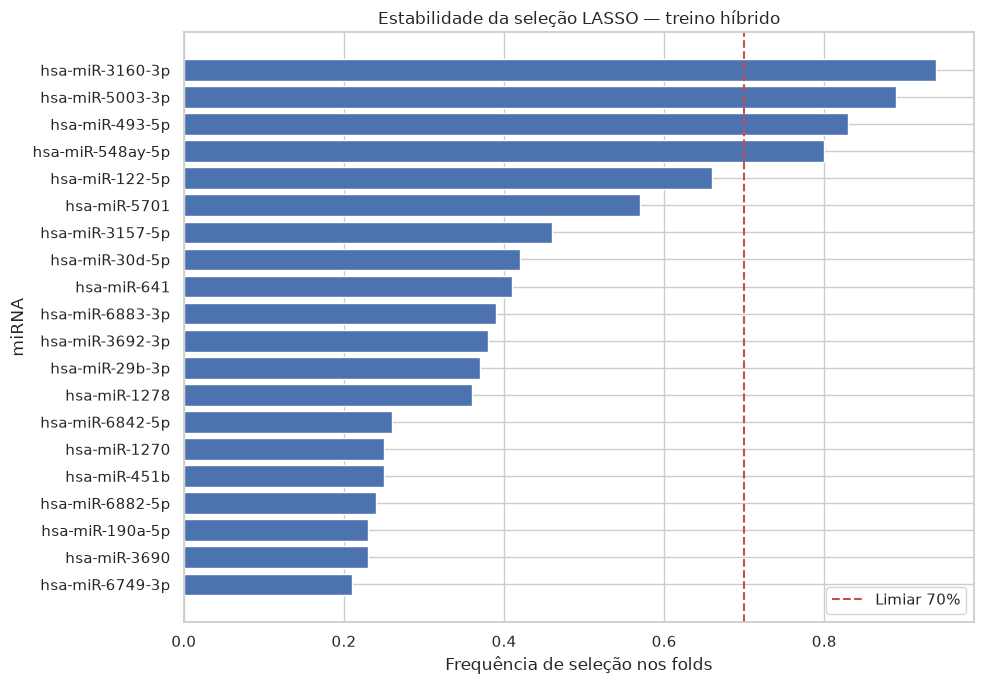

In [9]:
# Conta em quantos folds cada miRNA foi selecionado pelo LASSO.
stability_counts = Counter()
n_folds = 0

# Reajusta o LASSO em cada fold de treino da validação cruzada.
for part_train, _ in cv.split(X_train, y_train):
    fitted = make_lasso_svm("linear").fit(
        X_train.iloc[part_train], y_train.iloc[part_train]
    )
    support = fitted.named_steps["lasso"].get_support()
    for feature in X_train.columns[support]:
        stability_counts[feature] += 1
    n_folds += 1

# Frequência = folds em que o miRNA foi selecionado / total de folds.
stability = pd.DataFrame(
    [
        {"feature": feature, "n_folds": count, "frequency": count / n_folds}
        for feature, count in stability_counts.items()
    ]
).sort_values(["frequency", "feature"], ascending=[False, True])

stability.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_estabilidade_lasso.csv", index=False
)

# Indicadores de estabilidade: frequência máxima e limiares de 50% e 70%.
max_frequency = stability["frequency"].max() if not stability.empty else 0.0
n_stable_70 = int((stability["frequency"] >= 0.70).sum())
n_stable_50 = int((stability["frequency"] >= 0.50).sum())

print(f"Folds avaliados: {n_folds}")
print(f"miRNAs selecionados ao menos uma vez: {len(stability)}")
print(f"Frequência máxima de seleção: {max_frequency:.1%}")
print(f"miRNAs com frequência >= 70%: {n_stable_70}")
print(f"miRNAs com frequência >= 50%: {n_stable_50}")

display(stability.head(20).round(3))

# Gráfico dos 20 miRNAs mais frequentes nos folds.
top_stability = stability.head(20).iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(top_stability["feature"], top_stability["frequency"], color="#4c72b0")
plt.axvline(0.70, color="#c44e52", linestyle="--", label="Limiar 70%")
plt.xlabel("Frequência de seleção nos folds")
plt.ylabel("miRNA")
plt.title("Estabilidade da seleção LASSO — treino híbrido")
plt.legend()
plt.tight_layout()
plt.show()

## Etapa 5 — Modelo final e assinatura

O modelo final é treinado nas 32 amostras do treino híbrido com a mesma configuração avaliada na CV. A assinatura é o conjunto de miRNAs com coeficiente LASSO não nulo; os pesos do SVM linear indicam a direção da contribuição de cada miRNA no hiperplano.

In [10]:
# Treina o modelo final em todas as amostras do treino híbrido.
final_model = make_lasso_svm("linear", C=1.0, alpha=0.05).fit(
    X_train, y_train
)

# Recupera a máscara do LASSO e os coeficientes do SVM linear.
support = final_model.named_steps["lasso"].get_support()
selected_features = X_train.columns[support]
svm_coefficients = final_model.named_steps["svm"].coef_.ravel()
lasso_coefficients = final_model.named_steps["lasso"].coef_[support]

# Monta a tabela da assinatura final.
signature = pd.DataFrame(
    {
        "feature": selected_features,
        "lasso_coefficient": lasso_coefficients,
        "svm_coefficient": svm_coefficients,
    }
)
# Ordena pelos pesos absolutos do SVM.
signature["abs_svm_coefficient"] = signature["svm_coefficient"].abs()
signature = signature.sort_values(
    "abs_svm_coefficient", ascending=False
).reset_index(drop=True)

signature.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_assinatura_mirnas.csv", index=False
)
print(f"miRNAs selecionados pelo LASSO final: {len(signature)}")
display(signature.round(4))

miRNAs selecionados pelo LASSO final: 23


,feature,lasso_coefficient,svm_coefficient,abs_svm_coefficient
0,hsa-miR-5003-3p,-0.1418,-0.4171,0.4171
1,hsa-miR-548ay-5p,0.1083,0.3267,0.3267
2,hsa-miR-493-5p,0.1104,0.2999,0.2999
3,hsa-miR-1278,0.0587,0.2764,0.2764
4,hsa-miR-122-5p,0.0627,0.2703,0.2703
5,hsa-miR-5701,0.0613,0.2495,0.2495
6,hsa-miR-6749-3p,0.0362,0.2427,0.2427
7,hsa-miR-6883-3p,-0.0405,-0.2391,0.2391
8,hsa-miR-3160-3p,-0.1157,-0.1717,0.1717
9,hsa-miR-3690,0.0262,0.1696,0.1696


## Etapa 6 — Teste no holdout híbrido

O modelo é congelado e aplicado às 10 amostras retidas (4 AR + 6 MG). Não há re-treino, re-escalonamento com dados do teste, re-seleção de features ou ajuste de limiar. O limiar permanece 0,5.

Como o teste contém duas coortes, o resultado é reportado **no conjunto todo e separadamente por coorte**. Essa separação é essencial: um AUC agregado pode esconder que o desempenho vem só de MG, por exemplo.

Métricas do holdout híbrido (10 amostras):
  accuracy: 0.600
  f1: 0.500
  auc: 0.520
  AUC IC95% bootstrap: [0.118, 0.917]
  Previstos como respondedores: 3/10
  Acurácia de um classificador trivial que prevê não-respondedor: 0.500


,coorte,n,n_R,accuracy,f1,auc,auc_ci_low,auc_ci_high
0,GSE106894,4,2,0.500,0.5,0.750,0.0,1.0
1,GSE131703,6,3,0.667,0.5,0.556,0.0,1.0



Relatório de classificação — holdout híbrido:
                 precision    recall  f1-score   support

Não-respondedor      0.571     0.800     0.667         5
    Respondedor      0.667     0.400     0.500         5

       accuracy                          0.600        10
      macro avg      0.619     0.600     0.583        10
   weighted avg      0.619     0.600     0.583        10



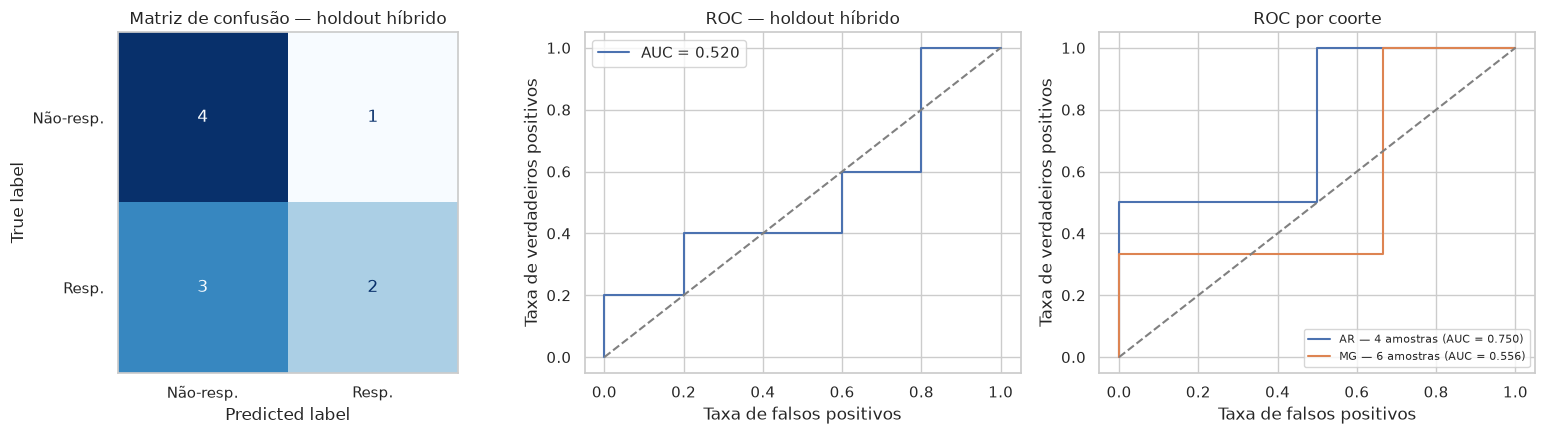

,coorte,amostra,y_true,y_pred,probabilidade
0,GSE106894,GSM2857229,0,1,0.882793
1,GSE106894,GSM2857230,0,0,0.080278
2,GSE106894,GSM2857236,1,0,0.096365
3,GSE106894,GSM2857237,1,1,0.980859
4,GSE131703,MG_NR4,0,0,0.261341
5,GSE131703,MG_R9,1,1,0.814480
6,GSE131703,MG_NR15,0,0,0.000704
7,GSE131703,MG_R12,1,0,0.070975
8,GSE131703,MG_NR5,0,0,0.209680
9,GSE131703,MG_R15,1,0,0.014990


In [11]:
# Aplica o modelo congelado ao holdout híbrido, sem re-treino ou ajuste.
y_prob_holdout = final_model.predict_proba(X_test)[:, 1]
y_pred_holdout = final_model.predict(X_test)

# Calcula as métricas do conjunto todo e o IC bootstrap da AUC.
holdout_metrics = _metrics(y_test, y_pred_holdout, y_prob_holdout)
auc_low, auc_high = bootstrap_auc_ci(y_test.values, y_prob_holdout)

print("Métricas do holdout híbrido (10 amostras):")
for metric, value in holdout_metrics.items():
    print(f"  {metric}: {value:.3f}")
print(f"  AUC IC95% bootstrap: [{auc_low:.3f}, {auc_high:.3f}]")
print(
    f"  Previstos como respondedores: "
    f"{int(y_pred_holdout.sum())}/{len(y_pred_holdout)}"
)
print(
    "  Acurácia de um classificador trivial que prevê não-respondedor: "
    f"{accuracy_score(y_test, np.zeros_like(y_test)):.3f}"
)

# Métricas por coorte, usando o mesmo modelo congelado.
def evaluate_domain(domain: str) -> dict:
    '''Calcula métricas do holdout restritas a uma coorte.'''
    mask = (meta_test["dataset"] == domain).to_numpy()
    y_true_domain = y_test.to_numpy()[mask]
    y_pred_domain = y_pred_holdout[mask]
    y_prob_domain = y_prob_holdout[mask]
    low, high = bootstrap_auc_ci(y_true_domain, y_prob_domain)
    return {
        "coorte": domain,
        "n": int(mask.sum()),
        "n_R": int(y_true_domain.sum()),
        ** _metrics(y_true_domain, y_pred_domain, y_prob_domain),
        "auc_ci_low": low,
        "auc_ci_high": high,
    }


domain_results = pd.DataFrame(
    [evaluate_domain(domain) for domain in ["GSE106894", "GSE131703"]]
)
display(domain_results.round(3))

# Relatório de precisão, recall e F1 por classe.
print("\nRelatório de classificação — holdout híbrido:")
print(
    classification_report(
        y_test,
        y_pred_holdout,
        target_names=["Não-respondedor", "Respondedor"],
        digits=3,
        zero_division=0,
    )
)

# Matriz de confusão e curvas ROC (conjunto todo e por coorte).
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

cm = confusion_matrix(y_test, y_pred_holdout)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Não-resp.", "Resp."],
).plot(cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Matriz de confusão — holdout híbrido")
axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, y_prob_holdout)
axes[1].plot(
    fpr, tpr, label=f"AUC = {holdout_metrics['auc']:.3f}", color="#4c72b0"
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("Taxa de falsos positivos")
axes[1].set_ylabel("Taxa de verdadeiros positivos")
axes[1].set_title("ROC — holdout híbrido")
axes[1].legend()

for domain, color, label in [
    ("GSE106894", "#4c72b0", "AR — 4 amostras"),
    ("GSE131703", "#dd8452", "MG — 6 amostras"),
]:
    mask = (meta_test["dataset"] == domain).to_numpy()
    y_true_domain = y_test.to_numpy()[mask]
    y_prob_domain = y_prob_holdout[mask]
    fpr_d, tpr_d, _ = roc_curve(y_true_domain, y_prob_domain)
    auc_d = roc_auc_score(y_true_domain, y_prob_domain)
    axes[2].plot(fpr_d, tpr_d, color=color, label=f"{label} (AUC = {auc_d:.3f})")
axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[2].set_xlabel("Taxa de falsos positivos")
axes[2].set_ylabel("Taxa de verdadeiros positivos")
axes[2].set_title("ROC por coorte")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Salva as previsões por amostra para auditoria.
previsoes = pd.DataFrame(
    {
        "coorte": meta_test["dataset"].to_numpy(),
        "amostra": X_test.index,
        "y_true": y_test.to_numpy(),
        "y_pred": y_pred_holdout,
        "probabilidade": y_prob_holdout,
    }
)
previsoes.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_previsoes_holdout.csv", index=False
)
display(previsoes)

## Etapa 7 — De onde vem o ganho? Ablação de volume e domínio

Um AUC melhor no holdout híbrido pode ter origens diferentes. Esta seção ajusta o mesmo pipeline em recortes específicos do treino e avalia nos mesmos recortes de teste:

| Configuração | O que isola |
|---|---|
| AR (8) → AR (4) | mesma doença, treino pequeno |
| MG (24) → MG (6) | mesma doença, treino maior |
| AR (8) → MG (6) | troca de doença, treino pequeno (análogo ao notebook 1) |
| MG (24) → AR (4) | troca de doença, treino maior |
| Híbrido (32) → AR (4) | efeito de adicionar MG ao treino, testando AR |
| Híbrido (32) → MG (6) | efeito de adicionar AR ao treino, testando MG |
| Híbrido (32) → Híbrido (10) | resultado principal deste notebook |

**Leitura esperada:** se MG→MG for muito superior a AR→MG, o ganho é compatibilidade de domínio. Se o treino híbrido superar os treinos de uma doença só em ambos os testes, o ganho é volume/interação. Se nada superar claramente o acaso, a hipótese de limitação do modelo linear ganha força.

In [12]:
def evaluate_config(
    name: str,
    config_train_idx: np.ndarray,
    config_test_idx: np.ndarray,
) -> dict:
    '''Ajusta o pipeline no treino da configuração e avalia no teste dela.'''
    model = make_lasso_svm("linear", C=1.0, alpha=0.05)
    fitted = model.fit(
        X_all.iloc[config_train_idx], y_all.iloc[config_train_idx]
    )
    y_prob = fitted.predict_proba(X_all.iloc[config_test_idx])[:, 1]
    y_pred = fitted.predict(X_all.iloc[config_test_idx])
    y_true = y_all.iloc[config_test_idx].to_numpy()
    low, high = bootstrap_auc_ci(y_true, y_prob)

    return {
        "configuracao": name,
        "n_train": len(config_train_idx),
        "n_test": len(config_test_idx),
        "n_mirnas_selecionados": int(
            fitted.named_steps["lasso"].get_support().sum()
        ),
        **_metrics(y_true, y_pred, y_prob),
        "auc_ci_low": low,
        "auc_ci_high": high,
    }


# Configurações de ablação sobre a divisão principal.
ABLATION_CONFIGS = {
    "AR (8) -> AR (4)": (ar_train, ar_test),
    "MG (24) -> MG (6)": (mg_train, mg_test),
    "AR (8) -> MG (6)": (ar_train, mg_test),
    "MG (24) -> AR (4)": (mg_train, ar_test),
    "Híbrido (32) -> AR (4)": (train_idx, ar_test),
    "Híbrido (32) -> MG (6)": (train_idx, mg_test),
    "Híbrido (32) -> Híbrido (10)": (train_idx, test_idx),
}

ablation_results = pd.DataFrame(
    [
        evaluate_config(name, config_train, config_test)
        for name, (config_train, config_test) in ABLATION_CONFIGS.items()
    ]
)
ablation_results.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_ablacao.csv", index=False
)
display(ablation_results.round(3))

,configuracao,n_train,n_test,n_mirnas_selecionados,accuracy,f1,auc,auc_ci_low,auc_ci_high
0,AR (8) -> AR (4),8,4,5,0.750,0.800,0.500,0.000,1.000
1,MG (24) -> MG (6),24,6,17,1.000,1.000,1.000,1.000,1.000
2,AR (8) -> MG (6),8,6,5,0.500,0.667,0.556,0.000,1.000
3,MG (24) -> AR (4),24,4,17,0.500,0.667,0.500,0.500,0.500
4,Híbrido (32) -> AR (4),32,4,23,0.500,0.500,0.750,0.000,1.000
5,Híbrido (32) -> MG (6),32,6,23,0.667,0.500,0.556,0.000,1.000
6,Híbrido (32) -> Híbrido (10),32,10,23,0.600,0.500,0.520,0.118,0.917


### Etapa 7.1 — Sensibilidade à divisão aleatória

Com apenas 4 amostras de AR e 6 de MG no teste, uma única divisão produz métricas muito granulares e ruidosas. Para não tirar conclusões de um sorteio específico, as mesmas configurações são repetidas em **50 divisões estratificadas** com sementes diferentes. O resultado reportado é a média ± desvio-padrão da AUC e a fração de divisões com AUC acima de 0,5.

In [13]:
# Reavalia as configurações em várias divisões estratificadas.
sensitivity_rows = []
for repetition, seed in enumerate(
    range(RANDOM_STATE, RANDOM_STATE + N_REPEATS)
):
    ar_tr, ar_te, mg_tr, mg_te = split_stratified_positions(
        y_all, N_AR, N_TEST_AR, N_TEST_MG, seed
    )
    hybrid_train = np.concatenate([ar_tr, mg_tr])
    hybrid_test = np.concatenate([ar_te, mg_te])
    configs = {
        "AR (8) -> AR (4)": (ar_tr, ar_te),
        "MG (24) -> MG (6)": (mg_tr, mg_te),
        "AR (8) -> MG (6)": (ar_tr, mg_te),
        "MG (24) -> AR (4)": (mg_tr, ar_te),
        "Híbrido (32) -> AR (4)": (hybrid_train, ar_te),
        "Híbrido (32) -> MG (6)": (hybrid_train, mg_te),
        "Híbrido (32) -> Híbrido (10)": (hybrid_train, hybrid_test),
    }

    for name, (config_train, config_test) in configs.items():
        model = make_lasso_svm("linear", C=1.0, alpha=0.05)
        fitted = model.fit(
            X_all.iloc[config_train], y_all.iloc[config_train]
        )
        y_prob = fitted.predict_proba(X_all.iloc[config_test])[:, 1]
        y_pred = fitted.predict(X_all.iloc[config_test])

        sensitivity_rows.append(
            {
                "repeticao": repetition,
                "seed": seed,
                "configuracao": name,
                "n_train": len(config_train),
                "n_test": len(config_test),
                **_metrics(
                    y_all.iloc[config_test].to_numpy(), y_pred, y_prob
                ),
            }
        )

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_sensibilidade_divisoes.csv", index=False
)

# Resumo por configuração: média, desvio e taxa de AUC > 0,5.
sensitivity_summary = (
    sensitivity.groupby("configuracao")
    .agg(
        n_repeticoes=("auc", "size"),
        n_train=("n_train", "first"),
        n_test=("n_test", "first"),
        accuracy_media=("accuracy", "mean"),
        accuracy_desvio=("accuracy", "std"),
        auc_media=("auc", "mean"),
        auc_desvio=("auc", "std"),
        auc_acima_0_5=("auc", lambda values: (values > 0.5).mean()),
    )
    .round(3)
)
sensitivity_summary.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_sensibilidade_resumo.csv"
)
display(sensitivity_summary)

,n_repeticoes,n_train,n_test,accuracy_media,accuracy_desvio,auc_media,auc_desvio,auc_acima_0_5
configuracao,,,,,,,,
AR (8) -> AR (4),50,8,4,0.440,0.240,0.390,0.332,0.22
AR (8) -> MG (6),50,8,6,0.500,0.082,0.519,0.275,0.54
Híbrido (32) -> AR (4),50,32,4,0.555,0.228,0.605,0.312,0.50
Híbrido (32) -> Híbrido (10),50,32,10,0.520,0.140,0.557,0.185,0.64
Híbrido (32) -> MG (6),50,32,6,0.497,0.170,0.529,0.228,0.54
MG (24) -> AR (4),50,24,4,0.500,0.000,0.475,0.113,0.06
MG (24) -> MG (6),50,24,6,0.603,0.199,0.640,0.249,0.72


## Etapa 8 — Comparação com o notebook 1

A tabela reúne as estimativas internas e externas dos dois notebooks. A linha de base é o Zero-Shot do notebook 1 (LASSO + SVM linear treinado em 12 AR e testado em 30 MG). As linhas do notebook 2 mostram o holdout híbrido e suas coortes separadas.

,notebook,n_treino,n_teste,accuracy,f1,auc
0,1 — Zero-Shot AR -> MG,12,30,0.500,0.000,0.436
1,1 — LOOCV interno AR,12,12,0.417,0.533,0.417
2,2 — LOOCV interno híbrido,32,32,0.562,0.562,0.535
3,2 — Holdout híbrido,32,10,0.600,0.500,0.520
4,2 — Holdout GSE106894 (4),32,4,0.500,0.500,0.750
5,2 — Holdout GSE131703 (6),32,6,0.667,0.500,0.556


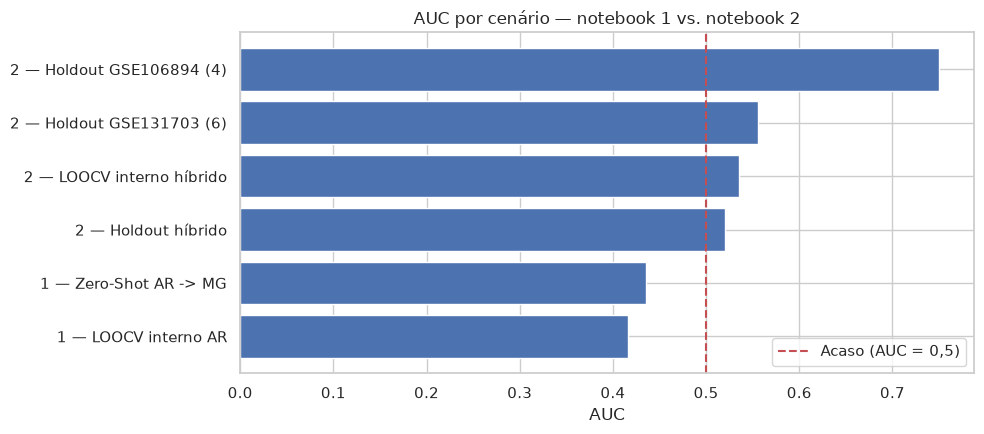

In [14]:
# Lê os resultados salvos pelo notebook 1, se existirem.
nb1_loocv_path = RESULTS_DIR / "vcp_loocv.csv"
nb1_summary_path = RESULTS_DIR / "vcp_resumo_metricas.csv"
nb1_loocv = pd.read_csv(nb1_loocv_path)
nb1_summary = pd.read_csv(nb1_summary_path)

nb1_zero = nb1_summary.loc[
    nb1_summary["etapa"].str.contains("Zero-Shot")
].iloc[0]
nb1_loo = nb1_loocv.loc[
    nb1_loocv["model"] == "LASSO + SVM linear"
].iloc[0]
nb2_loo = loocv_results.loc[
    loocv_results["model"] == "LASSO + SVM linear"
].iloc[0]

comparison_rows = [
    {
        "notebook": "1 — Zero-Shot AR -> MG",
        "n_treino": 12,
        "n_teste": 30,
        "accuracy": nb1_zero["accuracy"],
        "f1": nb1_zero["f1"],
        "auc": nb1_zero["auc"],
    },
    {
        "notebook": "1 — LOOCV interno AR",
        "n_treino": 12,
        "n_teste": 12,
        "accuracy": nb1_loo["accuracy"],
        "f1": nb1_loo["f1"],
        "auc": nb1_loo["auc"],
    },
    {
        "notebook": "2 — LOOCV interno híbrido",
        "n_treino": 32,
        "n_teste": 32,
        "accuracy": nb2_loo["accuracy"],
        "f1": nb2_loo["f1"],
        "auc": nb2_loo["auc"],
    },
    {
        "notebook": "2 — Holdout híbrido",
        "n_treino": len(train_idx),
        "n_teste": len(test_idx),
        "accuracy": holdout_metrics["accuracy"],
        "f1": holdout_metrics["f1"],
        "auc": holdout_metrics["auc"],
    },
]

# Acrescenta as coortes separadas do holdout.
for _, row in domain_results.iterrows():
    comparison_rows.append(
        {
            "notebook": f"2 — Holdout {row['coorte']} ({row['n']})",
            "n_treino": len(train_idx),
            "n_teste": int(row["n"]),
            "accuracy": row["accuracy"],
            "f1": row["f1"],
            "auc": row["auc"],
        }
    )

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(
    RESULTS_DIR / f"{RESULT_PREFIX}_comparacao_notebook1.csv", index=False
)
display(comparison.round(3))

# Gráfico de barras com as AUCs comparáveis.
plot_data = comparison.sort_values("auc")
plt.figure(figsize=(10, 4.5))
plt.barh(plot_data["notebook"], plot_data["auc"], color="#4c72b0")
plt.axvline(0.5, color="#c44e52", linestyle="--", label="Acaso (AUC = 0,5)")
plt.xlabel("AUC")
plt.title("AUC por cenário — notebook 1 vs. notebook 2")
plt.legend()
plt.tight_layout()
plt.show()

## Etapa 9 — Leitura dos resultados

### 1. O que o desenho permite concluir

O treino híbrido tem 32 amostras (8 AR + 24 MG) e o teste tem 10 (4 AR + 6 MG). Diferentemente do notebook 1, o teste contém amostras das mesmas coortes do treino; portanto, os números abaixo medem **holdout híbrido**, não transferência Zero-Shot.

### 2. Validação interna

- **CV repetida (100 folds), LASSO + SVM linear:** acurácia 0,491 ± 0,190; F1 0,477 ± 0,236; AUC 0,484 ± 0,224.
- **LOOCV agrupado, LASSO + SVM linear:** acurácia 0,562; F1 0,562; AUC 0,535 (IC bootstrap 95% 0,336–0,741).
- Para comparação, o notebook 1 tinha AUC LOOCV 0,417 e AUC Zero-Shot 0,436.
- **Estabilidade do LASSO:** 206 miRNAs foram selecionados ao menos uma vez; 4 atingiram frequência ≥ 70% (`hsa-miR-3160-3p` 94%, `hsa-miR-5003-3p` 89%, `hsa-miR-493-5p` 83%, `hsa-miR-548ay-5p` 80%). A assinatura é bem mais estável que no notebook 1 (lá, a frequência máxima foi 51% e nenhum miRNA passou de 70%), mas estabilidade de seleção não equivale a validade preditiva.

### 3. Holdout híbrido

- **Conjunto todo (10 amostras):** acurácia 0,600; F1 0,500; AUC 0,520 (IC 0,118–0,917); 3/10 previstos como respondedores. O classificador trivial que prevê todos como não-respondedores tem acurácia 0,500. O IC da AUC atravessa 0,5 com folga.
- **AR (4 amostras):** acurácia 0,500; F1 0,500; AUC 0,750 (IC 0–1).
- **MG (6 amostras):** acurácia 0,667; F1 0,500; AUC 0,556 (IC 0–1).

Com 4 e 6 amostras por coorte, as AUCs por coorte são extremamente granulares e os ICs bootstrap são largos por construção. Elas não sustentam afirmações fortes isoladamente.

### 4. De onde vem a diferença? (ablação + 50 divisões)

Médias de AUC nas 50 divisões estratificadas:

| Configuração | AUC média ± desvio | Fração com AUC > 0,5 |
|---|---:|---:|
| MG (24) → MG (6) | 0,640 ± 0,249 | 72% |
| Híbrido (32) → AR (4) | 0,605 ± 0,312 | 50% |
| Híbrido (32) → Híbrido (10) | 0,557 ± 0,185 | 64% |
| Híbrido (32) → MG (6) | 0,529 ± 0,228 | 54% |
| AR (8) → MG (6) | 0,519 ± 0,275 | 54% |
| MG (24) → AR (4) | 0,475 ± 0,113 | 6% |
| AR (8) → AR (4) | 0,390 ± 0,332 | 22% |

Leitura:

- **MG contra MG é o melhor cenário (0,640).** É também o cenário com mais dados de treino (24) e mesma doença/plataforma do teste. Não é possível separar completamente "mais dados" de "mesmo domínio" com este desenho, mas ambos apontam para um sinal específico da coorte MG.
- **Adicionar AR ao treino não melhorou MG:** Híbrido → MG (0,529) ficou abaixo de MG → MG (0,640). Ou seja, as amostras de AR não acrescentaram sinal transferível para MG e podem ter adicionado heterogeneidade.
- **MG não transfere para AR:** MG (24) → AR (4) ficou em 0,475 (abaixo do acaso, com apenas 6% das divisões acima de 0,5). Isso é evidência contra uma assinatura comum entre as doenças.
- **O ganho Híbrido → AR (0,605) é frágil:** tem o maior desvio (0,312) e só metade das divisões supera 0,5. Como MG → AR sozinho é 0,475, o ganho do híbrido provavelmente reflete regularização/estabilidade trazida por mais amostras, não transferência biológica de MG para AR.
- **AR contra AR é fraco (0,390):** com 8 amostras de treino, o pipeline linear não aprendeu um sinal reproduzível nem dentro da própria AR.

### 5. Sobre a hipótese avançada

O desempenho **não permaneceu exatamente na mesma faixa** do notebook 1: a AUC do holdout híbrido (0,520) e a AUC LOOCV interna (0,535) são um pouco maiores que o Zero-Shot (0,436), e a estabilidade do LASSO aumentou. Porém, o ganho é pequeno, os intervalos de confiança são largos e a decomposição mostra que ele é compatível com **volume de treino + proximidade de domínio (MG–MG)**, não com uma assinatura linear geral entre AR e MG.

Assim, os resultados **não confirmam** que o modelo linear captura a relação de forma generalizável. Eles são mais consistentes com a hipótese alternativa: o sinal linear, quando existe, é fraco e específico da coorte MG; para AR, o modelo fica próximo (ou abaixo) do acaso. Isso não prova que a relação seja não linear — o tamanho amostral e as diferenças de plataforma/tecido continuam confundindo —, mas também não oferece evidência de que este modelo estatístico seja suficiente.

### 6. Fatores externos que continuam em aberto

- **Plataforma e tecido:** AR é microarray de PBMC; MG é miRNA-seq de sangue total. A PCA do treino concentra 80,8% da variância nas duas primeiras componentes, compatível com estrutura global forte que pode ser dominada por coorte/plataforma.
- **Tamanho amostral:** 4 e 6 amostras de teste por coorte; as métricas variam muito entre divisões.
- **Seleção de features:** mesmo com estabilidade maior, 206 miRNAs foram selecionados ao menos uma vez; a assinatura final tem 23 features.
- **Sem harmonização entre domínios:** nenhum método de correção de lote (por exemplo, ComBat) foi aplicado.

### 7. Próximo teste decisivo

Para separar "relação não linear" de "sinal insuficiente", o próximo passo é rodar **modelos não lineares** (SVM RBF com tuning aninhado, random forest, gradient boosting) sob o **mesmo protocolo de 50 divisões** e comparar as distribuições de AUC com as do LASSO + SVM linear. Se os modelos não lineares subirem de forma consistente, há evidência de não linearidade. Se todos ficarem próximos de 0,5–0,6, a limitação é mais provavelmente de dados/sinal do que de forma funcional.

## Etapa 10 — Conclusões e limitações

1. **Holdout híbrido, não Zero-Shot.** Treino 32 (8 AR + 24 MG) e teste 10 (4 AR + 6 MG). O teste compartilha coortes com o treino; o resultado não é validação externa.
2. **Desempenho global próximo do acaso.** AUC 0,520 (IC 0,118–0,917) no holdout e 0,535 (IC 0,336–0,741) no LOOCV. Há melhora modesta em relação ao Zero-Shot do notebook 1 (0,436), mas dentro da variabilidade das 50 divisões (0,557 ± 0,185 no híbrido).
3. **A ablação aponta para domínio + volume.** MG → MG foi o melhor cenário (0,640; 72% das divisões acima de 0,5). MG → AR ficou em 0,475 e AR → AR em 0,390. Adicionar AR ao treino não melhorou o teste MG (0,529 vs. 0,640).
4. **A assinatura ficou mais estável, mas não necessariamente válida.** Quatro miRNAs atingiram frequência ≥ 70%, contra nenhum no notebook 1. Estabilidade de seleção com mais dados não garante poder preditivo.
5. **Hipótese avançada.** O padrão é mais compatível com um sinal linear fraco e específico da coorte MG do que com uma relação AR–MG generalizável. O resultado não prova não linearidade, mas também não sustenta que este modelo estatístico seja adequado.
6. **Limitações.** n pequeno no teste; plataformas e tecidos diferentes; ausência de harmonização; hiperparâmetros fixados a priori para comparabilidade; possível dominância de estrutura de coorte na PCA.
7. **Próximos passos.** Modelos não lineares sob o mesmo protocolo de divisões repetidas, harmonização entre domínios, validação aninhada e, idealmente, uma coorte verdadeiramente externa que não tenha participado de nenhuma etapa.